# Insurance Claims Analytics
**Case:** A fictional insurer wants to understand why claim settlement is delayed. The data is synthetic and used for practice. 

**Steps:** load, audit, clean, merge, create metrics, univariate, bivariate, multivariate analysis, root cause, recommendations, Power BI export.

## 1. Business context
Business question: where should the 30-day delay-improvement pilot start?

KPIs: settled claims, settlement rate, median / mean settlement days, delay rate (settled after 20 days), total claim value, verification days.

Note: pending and rejected claims have no settlement duration, so they are never counted as zero days. The 20-day threshold is only an assumption.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

## 2. Load the four tables
One customer has many policies, one policy has many claims and each claim has one processing record.

In [12]:
customers = pd.read_csv(r"customers_raw.csv")
policies = pd.read_csv(r"policies_raw.csv")
claims = pd.read_csv(r"claims_raw.csv")
processing = pd.read_csv(r"claim_processing_raw.csv")

In [13]:
print('Customers', customers.shape)
print('Policies', policies.shape)
print('Claims', claims.shape)
print('Processing', processing.shape)

Customers (8000, 5)
Policies (10000, 5)
Claims (15000, 7)
Processing (15000, 5)


In [14]:
customers.head()

,customer_id,age,gender,region,customer_since
0,C00001,25.0,Female,East,2022-09-26
1,C00002,62.0,Female,West,2022-06-06
2,C00003,56.0,Male,South,2024-07-04
3,C00004,44.0,Male,North,2020-01-02
4,C00005,44.0,Female,West,2023-03-13


In [15]:
policies.head()

,policy_id,customer_id,insurance_type,annual_premium,coverage_amount
0,P00001,C07202,Home,28990.0,300000
1,P00002,C05927,Home,8409.0,200000
2,P00003,C01656,Travel,13745.0,100000
3,P00004,C07967,Motor,8657.0,100000
4,P00005,C07942,Motor,18218.0,200000


In [16]:
claims.head()

,claim_id,policy_id,claim_date,claim_type,claim_amount,claim_status,settlement_date
0,CL000001,P01779,2025-02-03,Health,11321.0,Settled,2025-02-17
1,CL000002,P06862,2024-12-28,Motor,20277.0,Pending,NaN
2,CL000003,P00837,2025-03-09,Motor,25724.0,Settled,2025-03-27
3,CL000004,P07556,2025-05-27,Travel,7583.0,Settled,2025-06-23
4,CL000005,P00267,2024-02-13,Home,15782.0,Settled,2024-02-26


In [17]:
processing.head()

,claim_id,complexity,verification_days,approval_days,payment_days
0,CL000001,Medium,7.0,2,5
1,CL000002,Medium,5.0,6,3
2,CL000003,High,6.0,10,2
3,CL000004,High,11.0,12,4
4,CL000005,Medium,6.0,6,1


## 3. Data quality audit (before cleaning)
Count duplicates, missing values and unbalance labels first, so we can compare after cleaning. A missing settlement date is not always an error because open claims do not have one.

In [18]:
# cal duplicate rows in each table
print('Customers duplicates:', customers.duplicated().sum())
print('Policies duplicates:', policies.duplicated().sum())
print('Claims duplicates:', claims.duplicated().sum())
print('Processing duplicates:', processing.duplicated().sum())

Customers duplicates: 0
Policies duplicates: 0
Claims duplicates: 0
Processing duplicates: 0


In [19]:
# cal missing values in each table
print(customers.isna().sum())
print(policies.isna().sum())
print(claims.isna().sum())
print(processing.isna().sum())

customer_id        0
age               65
gender            80
region             0
customer_since     0
dtype: int64
policy_id           0
customer_id         0
insurance_type      0
annual_premium     90
coverage_amount     0
dtype: int64
claim_id              0
policy_id             0
claim_date            0
claim_type            0
claim_amount         95
claim_status          0
settlement_date    4227
dtype: int64
claim_id               0
complexity             0
verification_days    100
approval_days          0
payment_days           0
dtype: int64


### Category labels
Check the labels of each category column. Different spellings of the same label mean the column needs cleaning.

In [20]:
print(customers['region'].value_counts())
print(customers['gender'].value_counts(dropna=False))
print(policies['insurance_type'].value_counts())
print(claims['claim_type'].value_counts())
print(claims['claim_status'].value_counts())
print(processing['complexity'].value_counts())

region
South      2448
North      1885
West       1873
East       1654
SOUTH        39
north        37
East         34
 south       30
Name: count, dtype: int64
gender
Female    3972
Male      3948
NaN         80
Name: count, dtype: int64
insurance_type
Health     3902
Motor      3515
Travel     1485
Home        958
health       42
travel       40
HOME         32
 MOTOR       26
Name: count, dtype: int64
claim_type
Health    5964
Motor     5347
Travel    2228
Home      1461
Name: count, dtype: int64
claim_status
Settled      10637
Pending       3002
Rejected      1181
 settled       136
 PENDING        28
rejected        16
Name: count, dtype: int64
complexity
Low       7143
Medium    5611
High      2246
Name: count, dtype: int64


In [21]:
# duplicate ids
print('Duplicate customer IDs:', customers.customer_id.duplicated().sum())
print('Duplicate policy IDs:', policies.policy_id.duplicated().sum())
print('Duplicate claim IDs:', claims.claim_id.duplicated().sum())

Duplicate customer IDs: 0
Duplicate policy IDs: 0
Duplicate claim IDs: 0


## 4. Clean each table
Raw files are not changed. Impossible values are first set to missing and then filled with a simple rule.

### 4.1 Customers
Remove duplicate customers, fix region labels, and replace ages outside 18-100 with the median age of the same region.

In [22]:
# remove duplicate customers
customers = customers.drop_duplicates(subset='customer_id').copy()
customers.shape

(8000, 5)

In [23]:
# make the region labels same
customers['region'] = customers['region'].str.strip().str.title()
customers['region'].value_counts()

region
South    2517
North    1922
West     1873
East     1688
Name: count, dtype: int64

In [24]:
# missing gender
customers['gender'] = customers['gender'].fillna('Unknown')
customers['gender'].value_counts()

gender
Female     3972
Male       3948
Unknown      80
Name: count, dtype: int64

In [25]:
# The ages below 18 or above 100 are not valid, So make them missing
invalid_age = (customers['age'] < 18) | (customers['age'] > 100)
print('Invalid ages:', invalid_age.sum())
customers.loc[invalid_age, 'age'] = np.nan
print('Missing ages before filling:', customers['age'].isna().sum())

Invalid ages: 0
Missing ages before filling: 65


In [26]:
# fill the missing age with the median age of the same region
customers['age'] = customers['age'].fillna(customers.groupby('region')['age'].transform('median'))
print('Missing ages after filling:', customers['age'].isna().sum())

Missing ages after filling: 0


In [27]:
# customer_since to date format
customers['customer_since'] = pd.to_datetime(customers['customer_since'], errors='coerce')
customers['customer_since'].isna().sum()

np.int64(0)

### 4.2 Policies
Fix insurance type labels. Premiums that are missing/zero/negative are replaced with the median premium of the same insurance type.

In [28]:
policies['insurance_type'] = policies['insurance_type'].str.strip().str.title()
policies['insurance_type'].value_counts()

insurance_type
Health    3944
Motor     3541
Travel    1525
Home       990
Name: count, dtype: int64

In [29]:
# keep a flag for the rows we are going to fill
policies['premium_imputed'] = policies['annual_premium'].isna() | (policies['annual_premium'] <= 0)
print('Premiums to fix:', policies['premium_imputed'].sum())

policies.loc[policies['annual_premium'] <= 0, 'annual_premium'] = np.nan
policies['annual_premium'] = policies['annual_premium'].fillna(policies.groupby('insurance_type')['annual_premium'].transform('median'))
print('Missing premiums after filling:', policies['annual_premium'].isna().sum())

Premiums to fix: 90
Missing premiums after filling: 0


In [30]:
print('Invalid coverage:', (policies['coverage_amount'] <= 0).sum())

Invalid coverage: 0


### 4.3 Claims
Remove duplicate claim IDs, fix status labels and convert dates. Claim amounts of zero or less and settlement dates earlier than submission are invalid. Settled claims without a valid date are not given an invented date.

In [31]:
claims = claims.drop_duplicates(subset='claim_id').copy()
claims['claim_status'] = claims['claim_status'].str.strip().str.title()
claims['claim_type'] = claims['claim_type'].str.strip().str.title()
print(claims.shape)
print(claims['claim_status'].value_counts())

(15000, 7)
claim_status
Settled     10773
Pending      3030
Rejected     1197
Name: count, dtype: int64


In [32]:
# convert the dates
claims['claim_date'] = pd.to_datetime(claims['claim_date'], errors='coerce')
claims['settlement_date'] = pd.to_datetime(claims['settlement_date'], errors='coerce')
claims.dtypes

claim_id                      str
policy_id                     str
claim_date         datetime64[us]
claim_type                    str
claim_amount              float64
claim_status                  str
settlement_date    datetime64[us]
dtype: object

In [33]:
# claim amount zero or less is not valid
print('Invalid claim amounts:', (claims['claim_amount'] <= 0).sum())
print('Missing claim amounts:', claims['claim_amount'].isna().sum())
claims.loc[claims['claim_amount'] <= 0, 'claim_amount'] = np.nan

Invalid claim amounts: 12
Missing claim amounts: 95


In [34]:
# settlement date should not be before claim date
claims['date_issue'] = claims['settlement_date'] < claims['claim_date']
print('Date issues:', claims['date_issue'].sum())
claims.loc[claims['date_issue'], 'settlement_date'] = pd.NaT

Date issues: 0


In [35]:
# check the status against missing settlement date
pd.crosstab(claims['claim_status'], claims['settlement_date'].isna())

settlement_date,False,True
claim_status,,
Pending,0,3030
Rejected,0,1197
Settled,10773,0


### 4.4 Processing
Fix labels. Negative stage days are set to missing and filled with the median of the same complexity.

In [36]:
processing['complexity'] = processing['complexity'].str.strip().str.title()
processing['complexity'].value_counts()

complexity
Low       7143
Medium    5611
High      2246
Name: count, dtype: int64

In [37]:
# negative days are not possible
print('Negative verification days:', (processing['verification_days'] < 0).sum())
print('Negative approval days:', (processing['approval_days'] < 0).sum())
print('Negative payment days:', (processing['payment_days'] < 0).sum())
processing.loc[processing['verification_days'] < 0, 'verification_days'] = np.nan
print(processing.isna().sum())

Negative verification days: 0
Negative approval days: 0
Negative payment days: 0
claim_id               0
complexity             0
verification_days    100
approval_days          0
payment_days           0
dtype: int64


In [38]:
# Since the verification days depend on complexity, so I fill with the median of the same complexity
processing['verification_days'] = processing['verification_days'].fillna(processing.groupby('complexity')['verification_days'].transform('median'))
processing['verification_days'].isna().sum()

np.int64(0)

### 4.5 Merge the tables
It join claims with policies, customers and processing. We use left join so that no claim is lost, and then check that the number of claims is the same.

In [39]:
df = claims.merge(policies, on='policy_id', how='left')
df = df.merge(customers, on='customer_id', how='left')
df = df.merge(processing, on='claim_id', how='left')

print('Claims before merge:', len(claims))
print('Rows after merge:', len(df))
print('Unique claims:', df['claim_id'].nunique())

Claims before merge: 15000
Rows after merge: 15000
Unique claims: 15000


In [40]:
df.isna().sum()

claim_id                0
policy_id               0
claim_date              0
claim_type              0
claim_amount          107
claim_status            0
settlement_date      4227
date_issue              0
customer_id             0
insurance_type          0
annual_premium          0
coverage_amount         0
premium_imputed         0
age                     0
gender                  0
region                  0
customer_since          0
complexity              0
verification_days       0
approval_days           0
payment_days            0
dtype: int64

In [41]:
# claim amount missing: fill with the median of the same insurance type
df['claim_amount'] = df['claim_amount'].fillna(df.groupby('insurance_type')['claim_amount'].transform('median'))
df['claim_amount'].isna().sum()

np.int64(0)

In [42]:
# make sure claim type and policy type should be the same
df['type_mismatch'] = df['claim_type'] != df['insurance_type']
print('Claim type different from policy type:', df['type_mismatch'].sum())

Claim type different from policy type: 149


### 4.6 Outliers
Large claims can be valid, so we only flag them. The limit (Q3 + 1.5 x IQR) is calculated separately for each insurance product.

In [43]:
q1 = df.groupby('insurance_type')['claim_amount'].transform('quantile', 0.25)
q3 = df.groupby('insurance_type')['claim_amount'].transform('quantile', 0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

df['amount_outlier'] = df['claim_amount'] > upper_limit
print('High amount flags:', df['amount_outlier'].sum())
print(df.groupby('insurance_type')['amount_outlier'].sum())

High amount flags: 688
insurance_type
Health    290
Home       57
Motor     244
Travel     97
Name: amount_outlier, dtype: int64


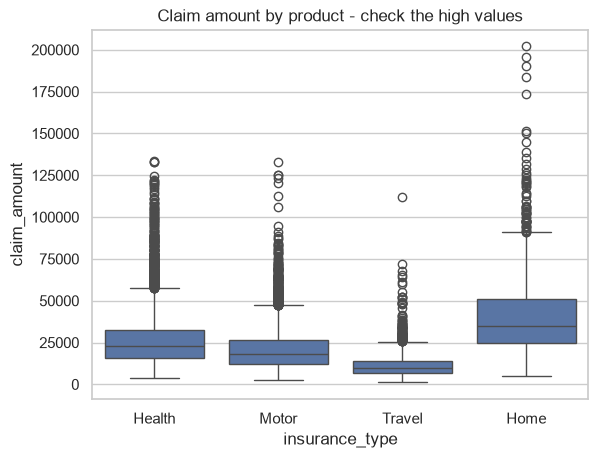

In [44]:
sns.boxplot(data=df, x='insurance_type', y='claim_amount')
plt.title('Claim amount by product - check the high values')
plt.show()

## 5. Feature engineering
Settlement days are calculated only for settled claims with a valid date. Delay flag = settlement days above 20. Other new columns: month, coverage and approval percentages, stage days, age group and claim-size group.

In [45]:
# settlement days
df['settlement_days'] = (df['settlement_date'] - df['claim_date']).dt.days
df.loc[df['claim_status'] != 'Settled', 'settlement_days'] = np.nan
df['is_settled'] = df['claim_status'] == 'Settled'
df['is_delayed'] = df['settlement_days'] > 20

In [46]:
# month columns
df['claim_month'] = df['claim_date'].dt.to_period('M').astype(str)
df['settlement_month'] = df['settlement_date'].dt.to_period('M').astype(str)

In [47]:
# claim amount as percentage of coverage
df['claim_to_coverage_pct'] = df['claim_amount'] / df['coverage_amount'] * 100

# total of the three recorded stages
df['stage_days'] = df['verification_days'] + df['approval_days'] + df['payment_days']

# days not explained by the three stages
df['other_wait_days'] = df['settlement_days'] - df['stage_days']

# how many years the customer has been with the company when the claim was made
df['tenure_years'] = ((df['claim_date'] - df['customer_since']).dt.days / 365).round(1)

In [48]:
# groups
df['age_group'] = pd.cut(df['age'], bins=[17, 30, 40, 50, 60, 100], labels=['18-30', '31-40', '41-50', '51-60', '60+'])
df['claim_size'] = pd.qcut(df['claim_amount'], 4, labels=['Small', 'Medium', 'Large', 'Very large'])

In [49]:
# table with only valid settled claims, used for all duration analysis
settled = df[df['is_settled'] & df['settlement_days'].notna()].copy()

print('Claims:', len(df))
print('Valid settled claims:', len(settled))
print('Settlement rate:', round(df['is_settled'].mean() * 100, 1))
print('Median settlement days:', settled['settlement_days'].median())
print('Delay rate:', round(settled['is_delayed'].mean() * 100, 1))

Claims: 15000
Valid settled claims: 10773
Settlement rate: 71.8
Median settlement days: 14.0
Delay rate: 12.1


## 6. Data quality after cleaning
Check the remaining problems. Non-zero values here are items to investigate, not automatic deletions.

In [50]:
print('Duplicate claim IDs:', df['claim_id'].duplicated().sum())
print('Claims with amount <= 0:', (df['claim_amount'] <= 0).sum())
print('Settled claims without settlement date:', (df['is_settled'] & df['settlement_date'].isna()).sum())
print('Claims without policy:', df['insurance_type'].isna().sum())
print('Claims without customer:', df['region'].isna().sum())
print('Claims without processing record:', df['complexity'].isna().sum())
print('Claims above coverage:', (df['claim_amount'] > df['coverage_amount']).sum())

Duplicate claim IDs: 0
Claims with amount <= 0: 0
Settled claims without settlement date: 0
Claims without policy: 0
Claims without customer: 0
Claims without processing record: 0
Claims above coverage: 15


In [51]:
df.isna().sum()[df.isna().sum() > 0]

settlement_date     4227
settlement_days     4227
settlement_month    4227
other_wait_days     4227
dtype: int64

# A. Univariate analysis
Look at each important column on its own: what is typical, how spread out it is, and whether there are unusual values.

## 7.1 Customer age
Histogram and age group share to understand the age mix of customers who claim.

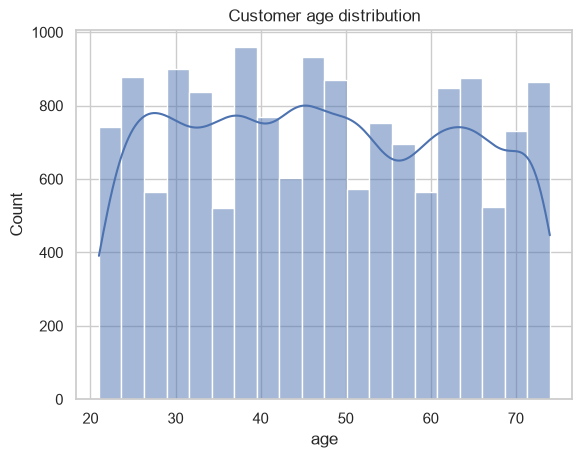

Median age: 47.0


In [52]:
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Customer age distribution')
plt.show()
print('Median age:', df['age'].median())

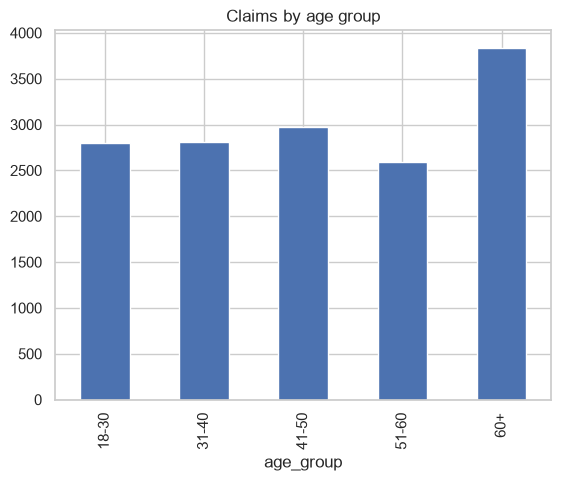

In [53]:
df['age_group'].value_counts().sort_index().plot(kind='bar')
plt.title('Claims by age group')
plt.show()

This is the age profile of claimants only, not of all customers. Compare with the customer master before taking action.

## 7.2 Annual premium
Distribution of premium overall and by product.

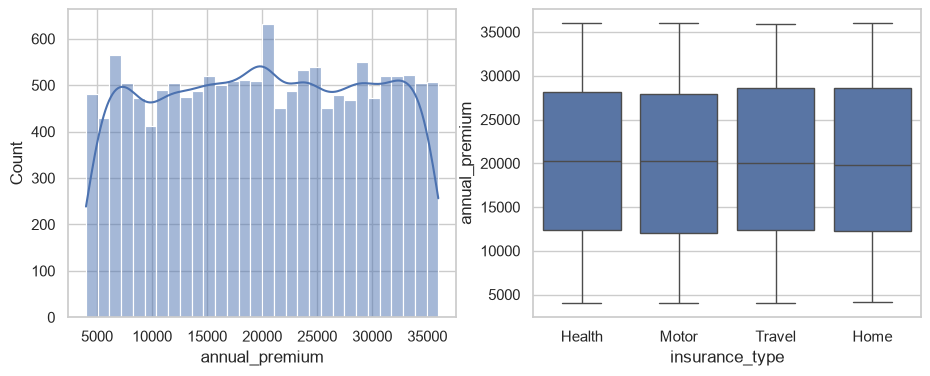

Median premium: 20203.5


In [55]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['annual_premium'], bins=30, kde=True, ax=ax[0])
sns.boxplot(data=df, x='insurance_type', y='annual_premium', ax=ax[1])
plt.show()
print('Median premium:', df['annual_premium'].median())

A high premium is not necessarily wrong. Use product-wise benchmarks.

## 7.3 Claim amount
Compare mean, median and P90. If the mean is much higher than the median, a few large claims are pulling it up.

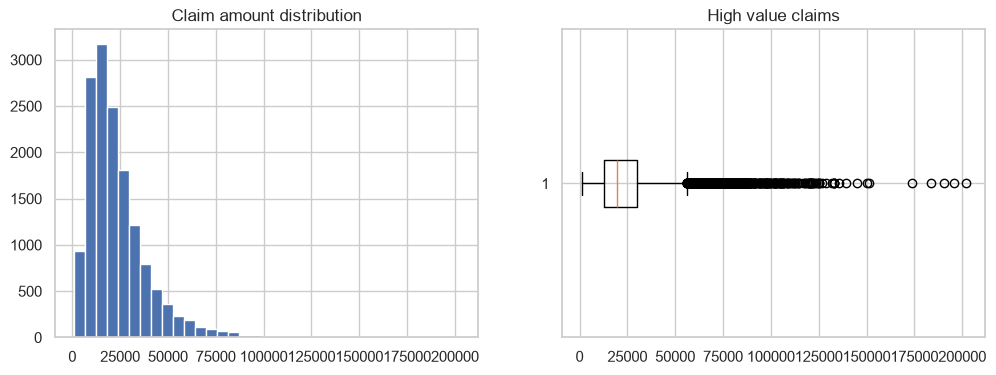

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['claim_amount'], bins=35)
ax[1].boxplot(df['claim_amount'], orientation='horizontal')
ax[0].set_title('Claim amount distribution')
ax[1].set_title('High value claims')
plt.show()

In [57]:
print('Median claim:', round(df['claim_amount'].median()))
print('Mean claim:', round(df['claim_amount'].mean()))
print('90th percentile:', round(df['claim_amount'].quantile(0.9)))

Median claim: 19599
Mean claim: 23832
90th percentile: 43941


Report the typical claim (median) and the high-value tail separately. Do not delete genuine large claims.

## 7.4 Claim amount as % of coverage
Find claims close to or above the policy coverage.

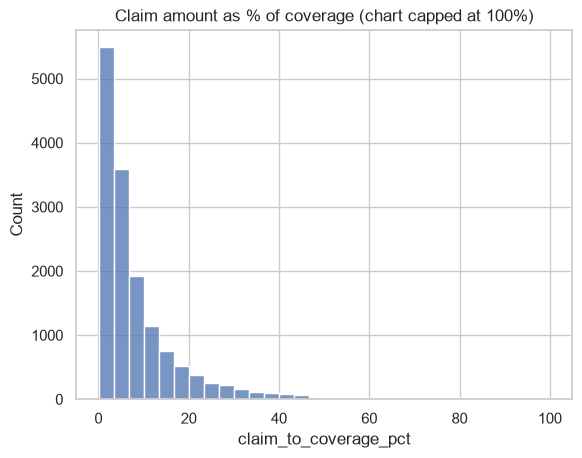

Median % of coverage: 5.0
Claims above 100% of coverage: 15


In [58]:
ratio = df['claim_to_coverage_pct']
sns.histplot(ratio.clip(upper=100), bins=30)
plt.title('Claim amount as % of coverage (chart capped at 100%)')
plt.show()
print('Median % of coverage:', round(ratio.median(), 1))
print('Claims above 100% of coverage:', (ratio > 100).sum())

Send above-coverage claims for a rule review. Do not delete them.

## 7.5 Verification vs approval days
Check which stage is longer.

In [59]:
print(df[['verification_days', 'approval_days', 'payment_days']].agg(['count', 'median', 'mean', 'max']).round(1))

        verification_days  approval_days  payment_days
count             15000.0        15000.0       15000.0
median                5.0            6.0           3.0
mean                  5.4            6.4           3.0
max                  15.0           18.0           7.0


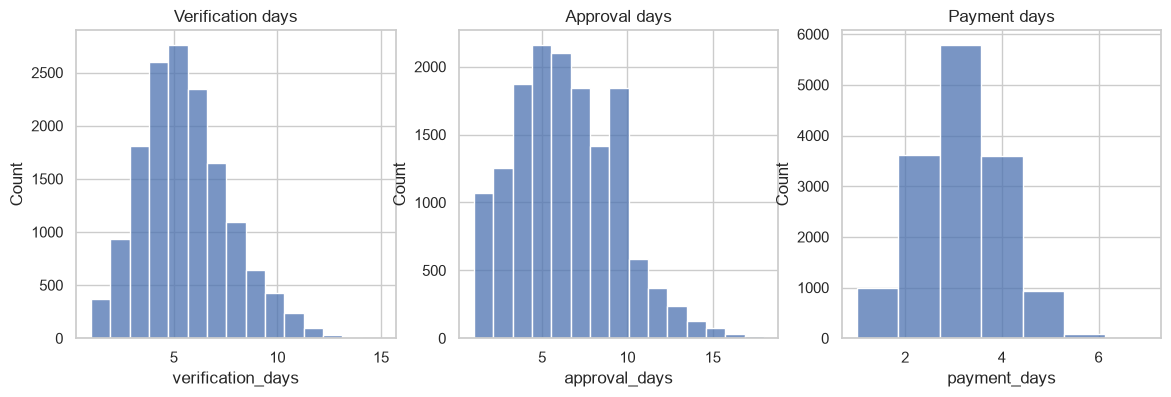

In [60]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df['verification_days'], bins=15, ax=ax[0])
sns.histplot(df['approval_days'], bins=15, ax=ax[1])
sns.histplot(df['payment_days'], bins=7, ax=ax[2])
ax[0].set_title('Verification days')
ax[1].set_title('Approval days')
ax[2].set_title('Payment days')
plt.show()

Review the longer stage first, but also check claim mix and documents before calling it the cause.

## 7.6 Settlement days
Distribution of days taken to settle (settled claims only).

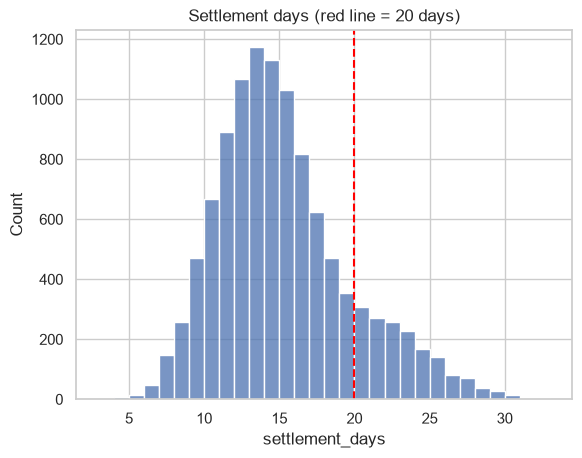

In [61]:
sns.histplot(settled['settlement_days'], bins=30)
plt.axvline(20, color='red', linestyle='--')
plt.title('Settlement days (red line = 20 days)')
plt.show()

In [62]:
print('Median:', settled['settlement_days'].median())
print('90th percentile:', settled['settlement_days'].quantile(0.9))
print('Share above 20 days:', round(settled['is_delayed'].mean() * 100, 1), '%')

Median: 14.0
90th percentile: 21.0
Share above 20 days: 12.1 %


A good median can hide a long tail. Track median, P90 and delay rate together.

## 7.7 Claim status
Number of settled, pending and rejected claims. Pending claims are not treated as settled.

claim_status
Settled     10773
Pending      3030
Rejected     1197
Name: count, dtype: int64


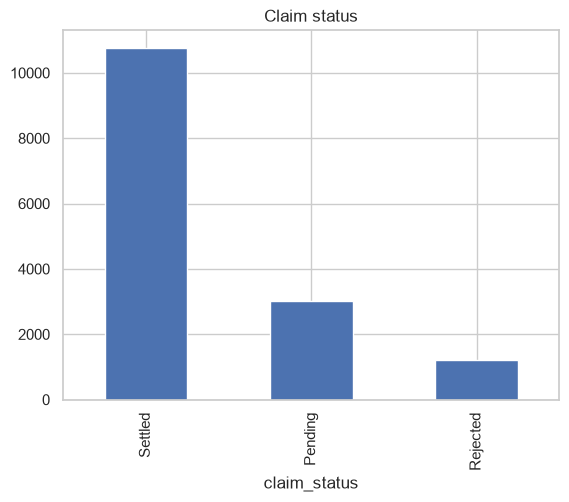

Pending share: 20.2 %


In [63]:
print(df['claim_status'].value_counts())
df['claim_status'].value_counts().plot(kind='bar')
plt.title('Claim status')
plt.show()
print('Pending share:', round((df['claim_status'] == 'Pending').mean() * 100, 1), '%')

Pending claims are a backlog. Their waiting time can be measured only if a reporting date is available.

## 7.8 Complexity and document status
Number of low / medium / high complexity claims and complete / incomplete documents.

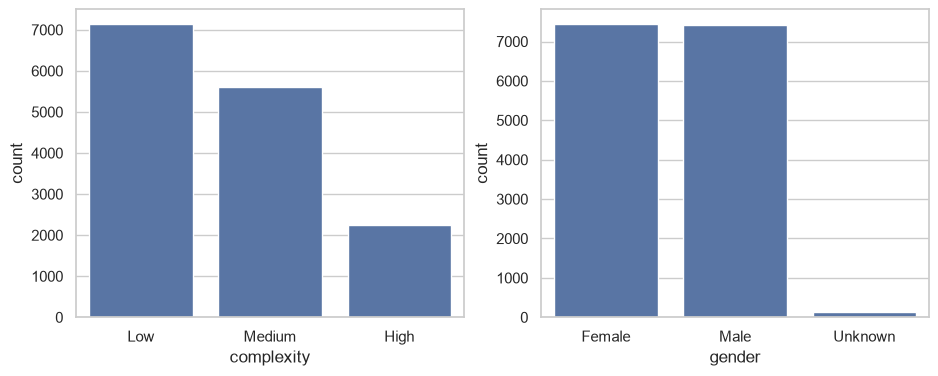

complexity
Low       0.476
Medium    0.374
High      0.150
Name: proportion, dtype: float64


In [64]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='complexity', order=['Low', 'Medium', 'High'], ax=ax[0])
sns.countplot(data=df, x='gender', ax=ax[1])
plt.show()
print(df['complexity'].value_counts(normalize=True).round(3))

Always look at complexity mix when comparing regions or teams.

# B. Bivariate analysis
Compare two columns at a time. Only settled claims are used for duration.

## 8.1 Settlement days by product
Which product has the highest median days and delay rate?

In [65]:
product_summary = settled.groupby('insurance_type').agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), mean_days=('settlement_days', 'mean'), delay_rate=('is_delayed', 'mean')).round(2)
product_summary

,claims,median_days,mean_days,delay_rate
insurance_type,,,,
Health,4297,15.0,15.92,0.15
Home,1095,13.0,13.95,0.10
Motor,3797,13.0,13.98,0.10
Travel,1584,13.0,14.11,0.11


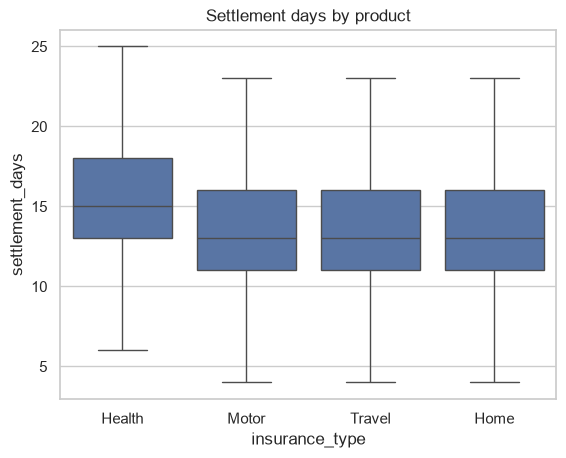

In [66]:
sns.boxplot(data=settled, x='insurance_type', y='settlement_days', showfliers=False)
plt.title('Settlement days by product')
plt.show()

Product differences may come from case mix. Check complexity and documents inside the product.

## 8.2 Settlement days by region
Which region has the highest delay rate?

In [67]:
region_summary = settled.groupby('region').agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), delay_rate=('is_delayed', 'mean')).round(3)
region_summary

,claims,median_days,delay_rate
region,,,
East,2184,16.0,0.183
North,2636,13.0,0.095
South,3418,13.0,0.103
West,2535,14.0,0.118


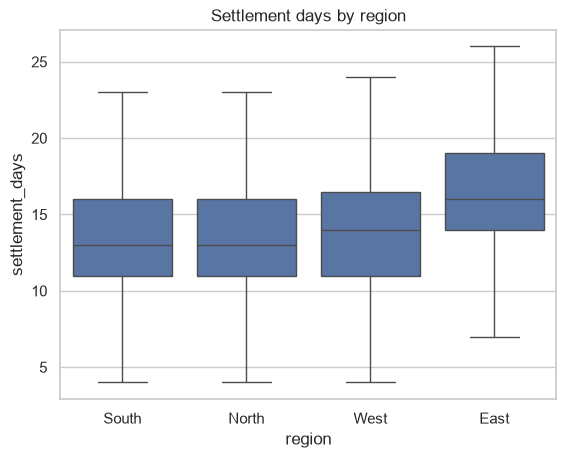

In [68]:
sns.boxplot(data=settled, x='region', y='settlement_days', showfliers=False)
plt.title('Settlement days by region')
plt.show()

Region may be affected by product mix. See the region x product view in 9.1.

## 8.3 Settlement days by complexity
Do complex claims take longer?

In [69]:
complexity_summary = settled.groupby('complexity').agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), delay_rate=('is_delayed', 'mean')).round(2)
complexity_summary

,claims,median_days,delay_rate
complexity,,,
High,1617,22.0,0.72
Low,5117,13.0,0.01
Medium,4039,13.0,0.02


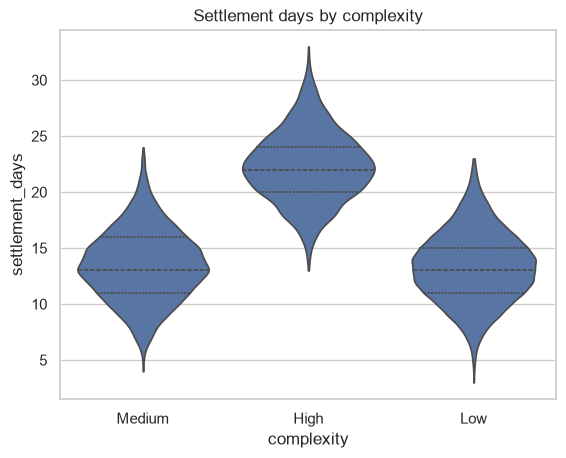

In [70]:
sns.violinplot(data=settled, x='complexity', y='settlement_days', inner='quartile', cut=0)
plt.title('Settlement days by complexity')
plt.show()

A difference is an association only. Check documents inside each complexity level.

## 8.4 Documents vs verification days
Do incomplete documents increase verification time?

In [75]:
settled[['settlement_days', 'verification_days', 'approval_days', 'payment_days']].corr().round(2)

,settlement_days,verification_days,approval_days,payment_days
settlement_days,1.00,0.76,0.85,0.23
verification_days,0.76,1.00,0.37,0.00
approval_days,0.85,0.37,1.00,-0.00
payment_days,0.23,0.00,-0.00,1.00


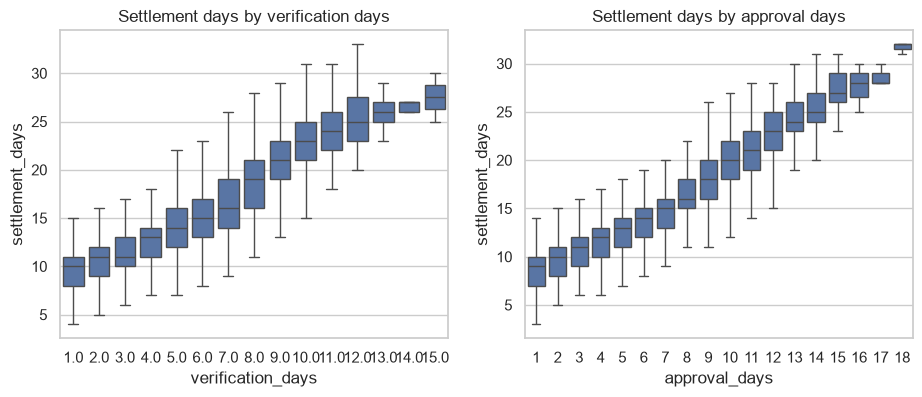

In [77]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=settled, x='verification_days', y='settlement_days', showfliers=False, ax=ax[0])
sns.boxplot(data=settled, x='approval_days', y='settlement_days', showfliers=False, ax=ax[1])
ax[0].set_title('Settlement days by verification days')
ax[1].set_title('Settlement days by approval days')
plt.show()

Possible pilot: a document checklist at first submission, then measure verification days.

## 8.5 Settlement days by team
Do teams differ after completing claims?

In [78]:
age_summary = settled.groupby('age_group', observed=True).agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), delay_rate=('is_delayed', 'mean')).round(3)
age_summary

,claims,median_days,delay_rate
age_group,,,
18-30,2021,14.0,0.115
31-40,1986,14.0,0.120
41-50,2187,14.0,0.125
51-60,1845,14.0,0.124
60+,2734,14.0,0.120


In [79]:
gender_summary = settled.groupby('gender').agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), delay_rate=('is_delayed', 'mean')).round(3)
gender_summary

,claims,median_days,delay_rate
gender,,,
Female,5374,14.0,0.118
Male,5314,14.0,0.123
Unknown,85,14.0,0.118


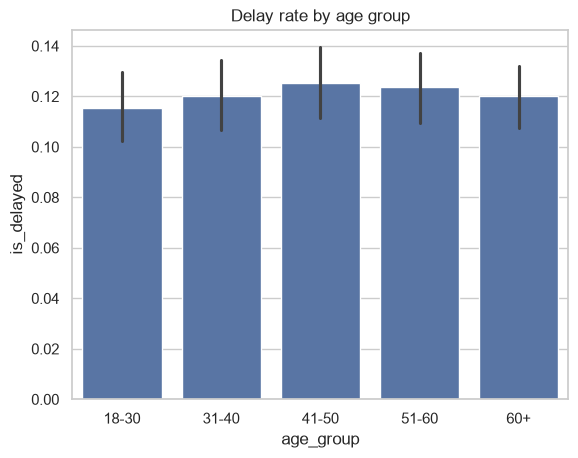

In [80]:
sns.barplot(data=settled, x='age_group', y='is_delayed')
plt.title('Delay rate by age group')
plt.show()

Teams may handle different complexity. Compare teams within the same complexity (see 9.2).

## 8.6 Claim amount vs settlement days
Are larger claims slower?

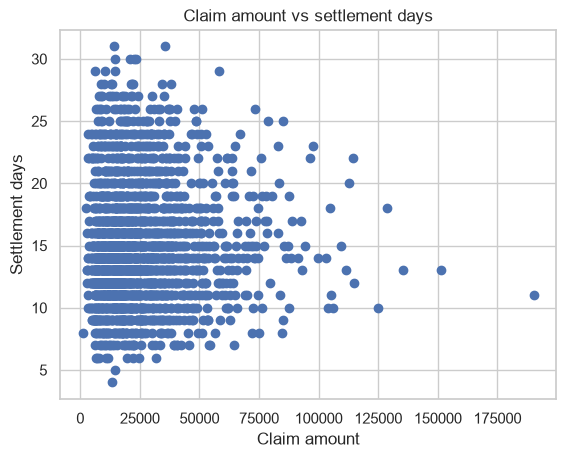

Correlation: 0.034


In [84]:
sample = settled.sample(2500, random_state=7)
plt.scatter(sample['claim_amount'], sample['settlement_days'], alpha=1.0)
plt.title('Claim amount vs settlement days')
plt.xlabel('Claim amount')
plt.ylabel('Settlement days')
plt.show()
print('Correlation:', round(settled['claim_amount'].corr(settled['settlement_days']), 3))

In [82]:
# compare by claim size group
settled.groupby('claim_size', observed=True)['settlement_days'].median()

claim_size
Small         14.0
Medium        14.0
Large         14.0
Very large    14.0
Name: settlement_days, dtype: float64

Correlation does not prove that a higher amount causes delay.

## 8.7 Submitted vs settled over time
Submitted claims are counted by submission month and settled claims by settlement month.

In [85]:
submitted = df.groupby('claim_month')['claim_id'].count()
submitted.name = 'submitted'
submitted

claim_month
2024-01    644
2024-02    593
2024-03    588
2024-04    612
2024-05    647
2024-06    618
2024-07    680
2024-08    621
2024-09    618
2024-10    675
2024-11    608
2024-12    588
2025-01    596
2025-02    557
2025-03    612
2025-04    646
2025-05    635
2025-06    658
2025-07    627
2025-08    659
2025-09    614
2025-10    617
2025-11    626
2025-12    661
Name: submitted, dtype: int64

In [86]:
# only valid settled claims that are counted by the month were settled
closed = settled.groupby('settlement_month')['claim_id'].count()
closed.name = 'settled'
closed

settlement_month
2024-01    251
2024-02    431
2024-03    406
2024-04    453
2024-05    471
2024-06    433
2024-07    484
2024-08    481
2024-09    449
2024-10    465
2024-11    444
2024-12    425
2025-01    434
2025-02    366
2025-03    463
2025-04    461
2025-05    474
2025-06    462
2025-07    469
2025-08    462
2025-09    424
2025-10    461
2025-11    432
2025-12    456
2026-01    216
Name: settled, dtype: int64

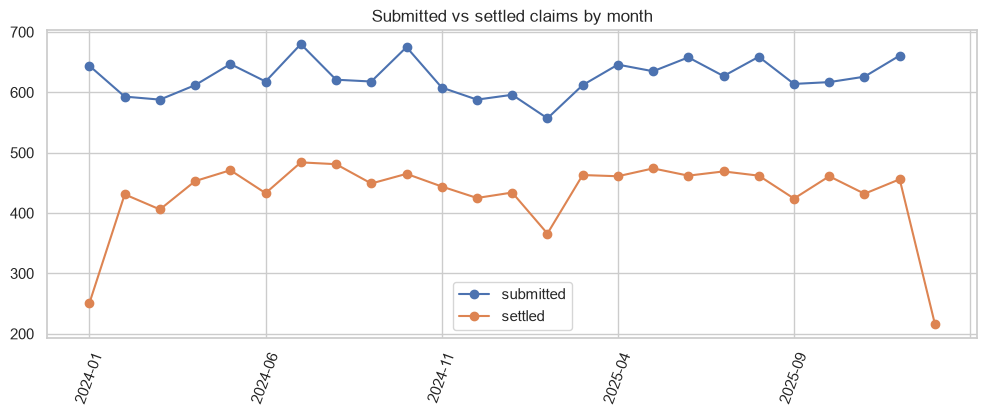

In [87]:
trend = pd.concat([submitted, closed], axis=1)
trend.plot(marker='o', figsize=(12, 4))
plt.title('Submitted vs settled claims by month')
plt.xticks(rotation=70)
plt.show()

Use settlement month to monitor throughput. The first and last months are incomplete.

## 8.8 Coverage vs claim amount
Do claims reach the coverage limit?

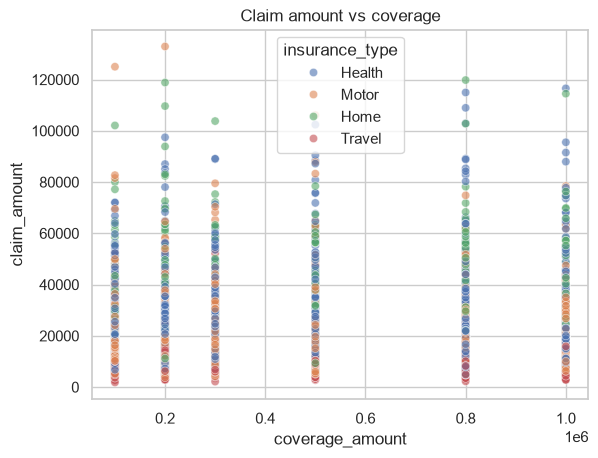

Claims above coverage: 15


In [89]:
sample = df[['coverage_amount', 'claim_amount', 'insurance_type']].sample(3000, random_state=3)
sns.scatterplot(data=sample, x='coverage_amount', y='claim_amount', hue='insurance_type', alpha=0.6)
plt.title('Claim amount vs coverage')
plt.show()
print('Claims above coverage:', (df['claim_amount'] > df['coverage_amount']).sum())

Check above-coverage claims against policy terms.

# C. Multivariate analysis
Compare three or more columns together. Check the number of claims in each cell, because small groups are unreliable.

## 9.1 Region x product delay rate
Does the regional difference remain inside the same product?

In [90]:
region_product = settled.pivot_table(index='region', columns='insurance_type', values='is_delayed', aggfunc='mean') * 100
region_product.round(1)

insurance_type,Health,Home,Motor,Travel
region,,,,
East,23.0,13.4,14.3,18.8
North,13.0,5.9,7.5,7.2
South,11.4,9.3,9.1,10.9
West,15.4,12.1,9.5,8.4


In [91]:
region_product_count = settled.pivot_table(index='region', columns='insurance_type', values='claim_id', aggfunc='count')
region_product_count

insurance_type,Health,Home,Motor,Travel
region,,,,
East,880,261,756,287
North,1061,253,932,390
South,1392,301,1212,513
West,964,280,897,394


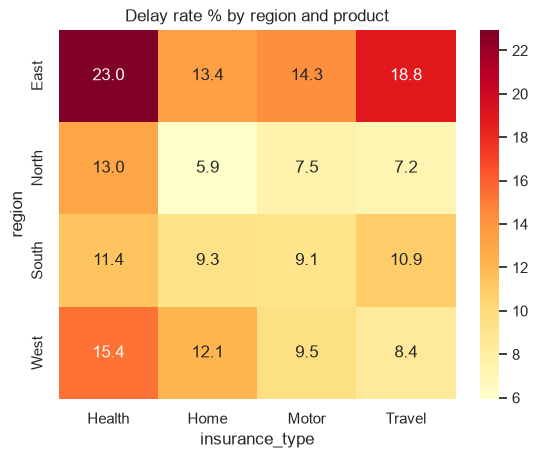

In [93]:
sns.heatmap(region_product, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Delay rate % by region and product')
plt.show()

Check document and complexity mix of the highest cell before using it for decisions.

## 9.2 Region x complexity
Does a region stay slower when claims have the same complexity?

In [94]:
region_complexity = settled.pivot_table(index='region', columns='complexity', values='is_delayed', aggfunc='mean') * 100
region_complexity = region_complexity[['Low', 'Medium', 'High']]
region_complexity.round(1)

complexity,Low,Medium,High
region,,,
East,5.4,5.5,93.4
North,0.2,0.5,63.4
South,0.7,0.6,68.6
West,0.3,0.3,68.5


In [95]:
region_complexity_count = settled.pivot_table(index='region', columns='complexity', values='claim_id', aggfunc='count')
region_complexity_count

complexity,High,Low,Medium
region,,,
East,318,995,871
North,383,1264,989
South,487,1682,1249
West,429,1176,930


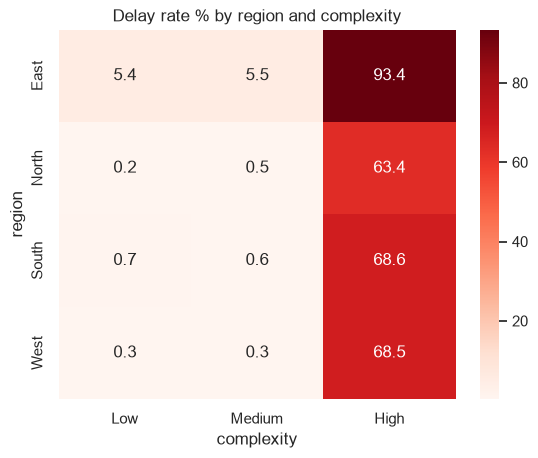

In [96]:
sns.heatmap(region_complexity, annot=True, fmt='.1f', cmap='Reds')
plt.title('Delay rate % by region and complexity')
plt.show()

If one region is still higher inside the same complexity level, review that region's process.

## 9.3 Product x complexity
Does product still matter after we compare the same complexity?

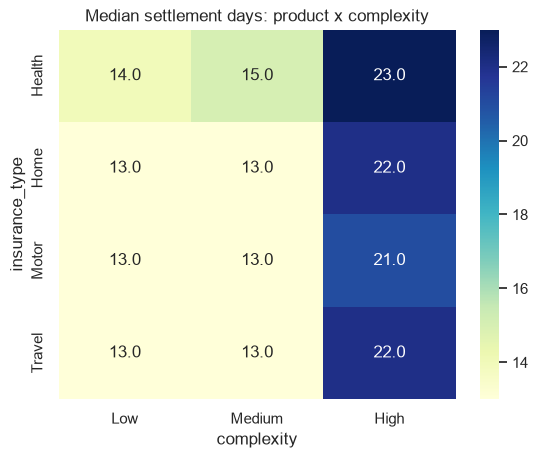

In [97]:
product_complexity = settled.pivot_table(index='insurance_type', columns='complexity', values='settlement_days', aggfunc='median')
product_complexity = product_complexity[['Low', 'Medium', 'High']]
sns.heatmap(product_complexity, annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Median settlement days: product x complexity')
plt.show()

In [98]:
complexity_stage = settled.groupby(['insurance_type', 'complexity']).agg(claims=('claim_id', 'count'), median_verification=('verification_days', 'median'), delay_rate=('is_delayed', 'mean')).round(2)
complexity_stage

claims  median_verification  delay_rate
insurance_type complexity                                         
Health         High           638                 10.0        0.84
               Low           2029                  6.0        0.03
               Medium        1630                  6.0        0.03
Home           High           156                  8.0        0.70
               Low            520                  4.0        0.00
               Medium         419                  4.0        0.00
Motor          High           567                  8.0        0.63
               Low           1804                  4.0        0.00
               Medium        1426                  4.0        0.01
Travel         High           256                  8.0        0.63
               Low            764                  4.0        0.00
               Medium         564                  4.0        0.01

If the product difference becomes small inside one complexity level, the first view was mainly caused by case mix.

## 9.4 Region x product x complexity
Ranked list of segments with the highest delay rate.

In [100]:
segments = settled.groupby(['region', 'insurance_type', 'complexity']).agg(claims=('claim_id', 'count'), median_days=('settlement_days', 'median'), delay_rate=('is_delayed', 'mean')).reset_index()
segments = segments[segments['claims'] >= 50]
segments['delay_pct'] = (segments['delay_rate'] * 100).round(1)
segments.sort_values('delay_pct', ascending=False).head(10)

,region,insurance_type,complexity,claims,median_days,delay_rate,delay_pct
0,East,Health,High,124,25.0,0.975806,97.6
6,East,Motor,High,103,23.0,0.922330,92.2
9,East,Travel,High,55,25.0,0.872727,87.3
36,West,Health,High,172,23.0,0.825581,82.6
24,South,Health,High,176,23.0,0.818182,81.8
12,North,Health,High,166,22.5,0.789157,78.9
39,West,Home,High,51,22.0,0.666667,66.7
33,South,Travel,High,88,21.0,0.613636,61.4
30,South,Motor,High,184,21.0,0.592391,59.2
45,West,Travel,High,56,21.0,0.589286,58.9


Choose a large enough segment for the pilot, not the smallest one with an extreme percentage.

## 9.5 Claim size x complexity
Does the amount-duration relationship change with complexity?

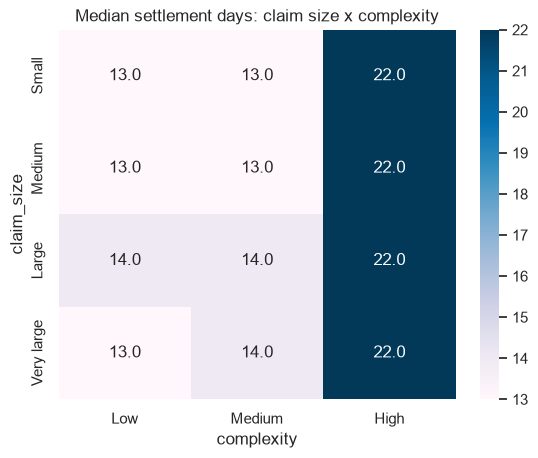

In [102]:
size_complexity = settled.pivot_table(index='claim_size', columns='complexity', values='settlement_days', aggfunc='median', observed=True)
size_complexity = size_complexity[['Low', 'Medium', 'High']]
sns.heatmap(size_complexity, annot=True, fmt='.1f', cmap='PuBu')
plt.title('Median settlement days: claim size x complexity')
plt.show()

This is descriptive only. Next, compare verification and approval within similar claim sizes.

## 9.6 Monthly volume by product
Is workload growth concentrated in one product?

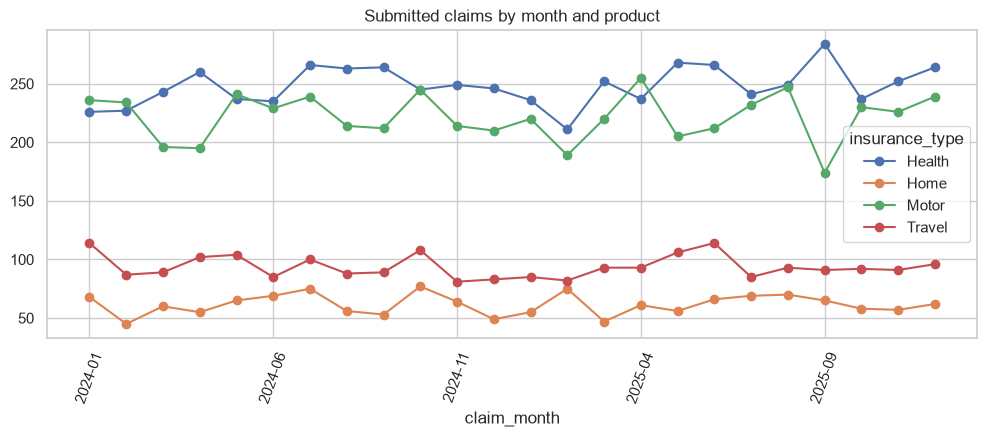

In [103]:
product_trend = df.pivot_table(index='claim_month', columns='insurance_type', values='claim_id', aggfunc='count')
product_trend.plot(figsize=(12, 4), marker='o')
plt.title('Submitted claims by month and product')
plt.xticks(rotation=70)
plt.show()

Use product volume trends for staffing plans. Do not conclude seasonality from a short period.

# D. Root cause and pilot selection
## 10. Where does the time go?
Split settlement days into verification days, approval days and other waiting days (settlement days minus the two stages).

In [104]:
settled[['verification_days', 'approval_days', 'payment_days', 'other_wait_days']].median()

verification_days    5.0
approval_days        6.0
payment_days         3.0
other_wait_days      0.0
dtype: float64

In [105]:
# other waiting days: is the settlement time fully explained by the three stages?
print(settled['other_wait_days'].describe())
print('Claims where stages do not add up:', (settled['other_wait_days'] != 0).sum())

count    10773.000000
mean        -0.002413
std          0.136238
min         -4.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.000000
Name: other_wait_days, dtype: float64
Claims where stages do not add up: 55


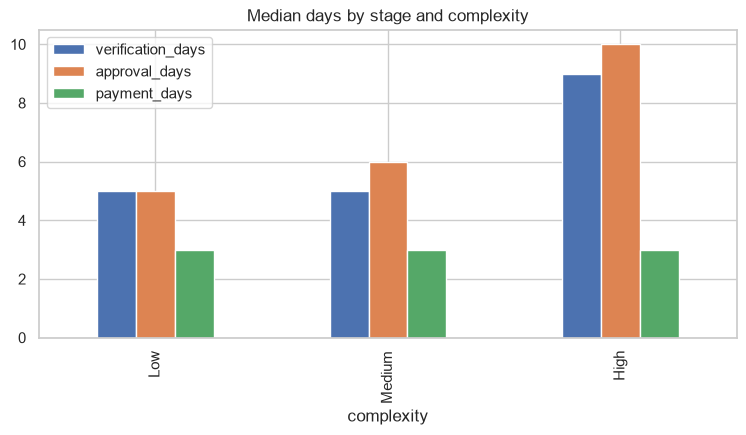

In [109]:
settled.groupby('complexity')[['verification_days', 'approval_days', 'payment_days']].median().loc[['Low', 'Medium', 'High']].plot(kind='bar', figsize=(9, 4))
plt.title('Median days by stage and complexity')
plt.show()

In [108]:
# compare delayed claims with on-time claims
settled['speed'] = np.where(settled['is_delayed'], 'Delayed', 'On time')
settled.groupby('speed')[['verification_days', 'approval_days', 'payment_days']].median()

,verification_days,approval_days,payment_days
speed,,,
Delayed,9.0,11.0,3.0
On time,5.0,6.0,3.0


The stage with the biggest difference between delayed and on-time claims is the best candidate for review. If other waiting days are zero, then the three stages explain the full settlement time.

## 11. Pilot selection
For each region x product x document segment with enough claims, excess delays = delayed claims - (claims x overall delay rate). The segment with the most excess delays is the best starting point.

In [110]:
overall_rate = settled['is_delayed'].mean()

pilot = settled.groupby(['region', 'insurance_type', 'complexity']).agg(claims=('claim_id', 'count'), delayed=('is_delayed', 'sum')).reset_index()
pilot = pilot[pilot['claims'] >= 50].copy()

pilot['delay_pct'] = (pilot['delayed'] / pilot['claims'] * 100).round(1)
pilot['excess_delays'] = (pilot['delayed'] - pilot['claims'] * overall_rate).round(0)
pilot = pilot.sort_values('excess_delays', ascending=False)
pilot.head(8)

,region,insurance_type,complexity,claims,delayed,delay_pct,excess_delays
24,South,Health,High,176,144,81.8,123.0
36,West,Health,High,172,142,82.6,121.0
12,North,Health,High,166,131,78.9,111.0
0,East,Health,High,124,121,97.6,106.0
30,South,Motor,High,184,109,59.2,87.0
6,East,Motor,High,103,95,92.2,83.0
42,West,Motor,High,150,85,56.7,67.0
18,North,Motor,High,130,70,53.8,54.0


## 12. Executive summary
The lines below are printed from the cleaned data.

In [111]:
print('Claims analysed:', len(df))
print('Settled claims:', len(settled))
print('Median settlement days:', settled['settlement_days'].median())
print('90th percentile settlement days:', settled['settlement_days'].quantile(0.9))
print('Delayed share (%):', round(settled['is_delayed'].mean() * 100, 1))
print('Slowest product (median):', settled.groupby('insurance_type')['settlement_days'].median().idxmax())
print('Highest delay region:', settled.groupby('region')['is_delayed'].mean().idxmax())
print('Highest delay complexity:', settled.groupby('complexity')['is_delayed'].mean().idxmax())
print('Pending claims:', (df['claim_status'] == 'Pending').sum())
print('Top pilot segment:', pilot.iloc[0]['region'], '|', pilot.iloc[0]['insurance_type'], '|', pilot.iloc[0]['complexity'])

Claims analysed: 15000
Settled claims: 10773
Median settlement days: 14.0
90th percentile settlement days: 21.0
Delayed share (%): 12.1
Slowest product (median): Health
Highest delay region: East
Highest delay complexity: High
Pending claims: 3030
Top pilot segment: South | Health | High


## 13. Action plan
1. Document checklist pilot in the top segment from section 11. Owner: claims intake lead. Measure: incomplete-document rate, verification days, delay rate.
2. Fast routing of high-complexity claims. Owner: verification manager. Measure: P90 verification days.
3. Track verification, approval and other waiting time by region and product every week. Owner: claims analyst.
4. Send updates to customers with old pending claims. Measure: complaints and satisfaction when available.